In [1]:

import numpy as np
import pandas as pd
from pathlib import Path

# Load processed Titanic datasets
data_path = Path("/kaggle/input")

train = pd.read_csv(next(data_path.rglob("titanic_train_processed.csv")))
test = pd.read_csv(next(data_path.rglob("titanic_test_processed.csv")))

X_train = train.drop(columns="Survived").values
y_train = train["Survived"].values

X_test = test.drop(columns="Survived").values
y_test = test["Survived"].values

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (712, 10) (712,)
Testing: (179, 10) (179,)


In [2]:

# Logistic Regression using Mini-Batch GD + Momentum

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

X = np.c_[np.ones(len(X_train)), X_train]

weights = np.zeros(X.shape[1])
velocity = np.zeros_like(weights)

lr = 0.01
momentum = 0.9
batch_size = 32
epochs = 500
loss_history = []
rng = np.random.default_rng(42)

for epoch in range(epochs):
    indices = rng.permutation(len(X))

    for start in range(0, len(X), batch_size):
        batch = indices[start:start + batch_size]
        xb, yb = X[batch], y_train[batch]

        predictions = sigmoid(xb @ weights)
        gradient = xb.T @ (predictions - yb) / len(yb)

        velocity = momentum * velocity + gradient
        weights -= lr * velocity

    p = np.clip(sigmoid(X @ weights), 1e-10, 1 - 1e-10)
    loss = -np.mean(y_train * np.log(p) +
                    (1 - y_train) * np.log(1 - p))
    loss_history.append(loss)

print("Mini-Batch GD + Momentum Training Completed!")
print("Final Training Loss:", loss_history[-1])
print("Learned Weights:", weights)


Mini-Batch GD + Momentum Training Completed!
Final Training Loss: 0.4362161812694994
Learned Weights: [-0.64670472 -0.95565511 -0.52194936 -0.2581493  -0.09269351  0.08951194
  0.63274    -0.63274     0.05413047  0.12125468 -0.12090087]


Accuracy : 0.8156424581005587
Precision: 0.8
Recall   : 0.6956521739130435
F1 Score : 0.7441860465116279
Test Loss: 0.46383907665005253


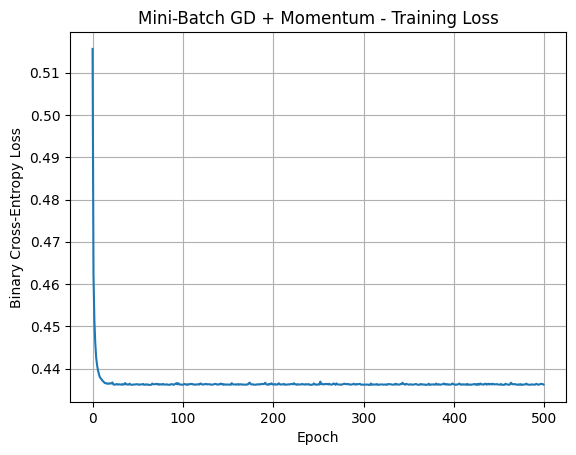

In [3]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# Test predictions
X_test_bias = np.c_[np.ones(len(X_test)), X_test]
probs = sigmoid(X_test_bias @ weights)
y_pred = (probs >= 0.5).astype(int)

# Binary Cross-Entropy Loss
p = np.clip(probs, 1e-10, 1 - 1e-10)
test_loss = -np.mean(y_test * np.log(p) +
                     (1 - y_test) * np.log(1 - p))

# Evaluation metrics
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))
print("Test Loss:", test_loss)

# Training Loss Curve
plt.plot(loss_history)
plt.title("Mini-Batch GD + Momentum - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True)
plt.show()
